In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("majdihbibi/tunisian-banknotes")

print("Path to dataset files:", path)

100%|██████████| 989M/989M [00:07<00:00, 146MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/majdihbibi/tunisian-banknotes/versions/1


In [ ]:
import os, glob, collections
racine = path
exts = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')
fichiers = [p for p in glob.glob(os.path.join(racine, '**', '*'), recursive=True) if os.path.isfile(p)]
imgs = [p for p in fichiers if p.lower().endswith(exts)]
autres = [p for p in fichiers if not p.lower().endswith(exts)]
print('Total fichiers:', len(fichiers), '| images:', len(imgs), '| autres:', len(autres))
compte = collections.Counter(os.path.relpath(os.path.dirname(p), racine) for p in imgs)
print('\n'.join(f'{k}: {v}' for k, v in sorted(compte.items())))
print('Exemples autres fichiers:', [os.path.relpath(p, racine) for p in autres[:10]])

Total fichiers: 662 | images: 662 | autres: 0
Dataset/test/10dt: 37
Dataset/test/20dt: 34
Dataset/test/50dt: 29
Dataset/test/5dt: 34
Dataset/train/10dt: 145
Dataset/train/20dt: 134
Dataset/train/50dt: 116
Dataset/train/5dt: 133
Exemples autres fichiers: []


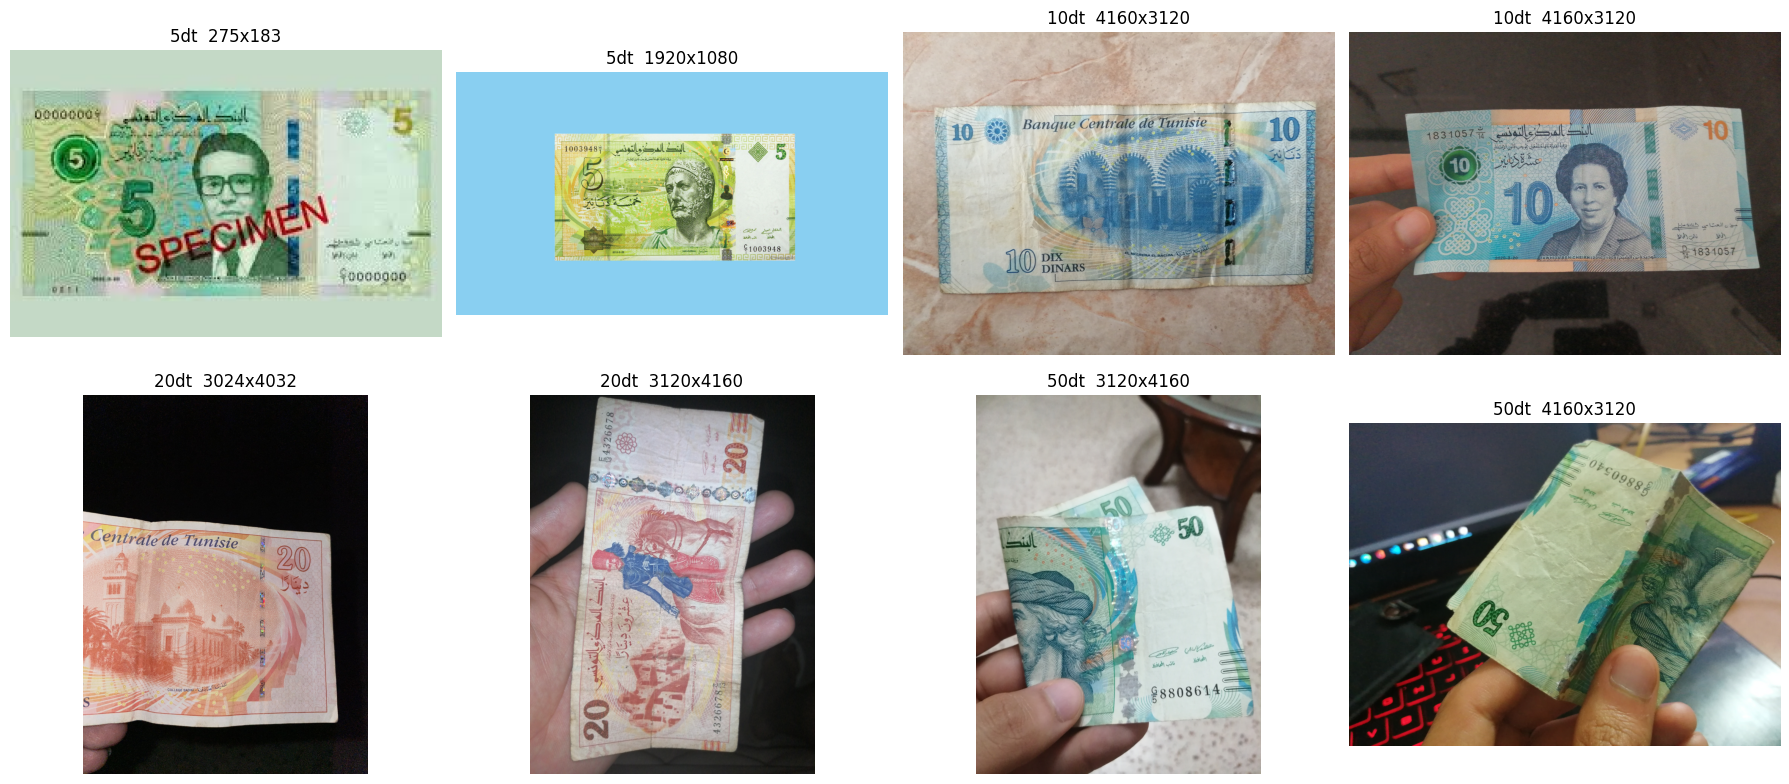

In [ ]:
import cv2, random, matplotlib.pyplot as plt
random.seed(0)
ech = [random.choice([p for p in imgs if f'/{c}/' in p]) for c in ['5dt', '10dt', '20dt', '50dt'] for _ in range(2)]
plt.figure(figsize=(18, 8))def _test(x):
    if x > 0:
            return 1
                return 0
                print(_test(3), _test(-1))
for i, p in enumerate(ech): im = cv2.imread(p); plt.subplot(2, 4, i + 1); plt.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB)); plt.title(f"{os.path.basename(os.path.dirname(p))}  {im.shape[1]}x{im.shape[0]}"); plt.axis('off')
plt.tight_layout(); plt.show()

In [ ]:
# =====================================================
# 1. Chargement des images (redimensionnées, côté max 512 px)
# =====================================================
import os, glob, time
import numpy as np
import cv2
import matplotlib.pyplot as plt

RACINE = os.path.join(path, 'Dataset')
CLASSES = ['5dt', '10dt', '20dt', '50dt']
TAILLE_MAX = 512

def charger_image(chemin, taille_max=TAILLE_MAX):
    # lecture directement réduite (plus rapide sur les photos 4000x3000)
    img = cv2.imread(chemin, cv2.IMREAD_REDUCED_COLOR_4)
    h, w = img.shape[:2]
    s = taille_max / max(h, w)
    return cv2.resize(img, (int(w * s), int(h * s)), interpolation=cv2.INTER_AREA)

def charger_split(split):
    X, y, chemins = [], [], []
    for i, c in enumerate(CLASSES):
        for p in sorted(glob.glob(os.path.join(RACINE, split, c, '*'))):
            X.append(charger_image(p))
            y.append(i)
            chemins.append(p)
    return X, np.array(y), chemins

t0 = time.time()
X_train, y_train, p_train = charger_split('train')
X_test, y_test, p_test = charger_split('test')
print(f'train : {len(X_train)} images | test : {len(X_test)} images | {time.time() - t0:.0f} s')
print('répartition train :', np.bincount(y_train), '| test :', np.bincount(y_test))

train : 528 images | test : 134 images | 33 s
répartition train : [133 145 134 116] | test : [34 37 34 29]
